This is the continuation of assignment notebook for modelling the datas. I created separate notebook for modelling because in previous notebook I added datas and worked on them every time while running it was uploading over 1 million datas. But since i supervised data and categorised for the part i want to use and divided datas per daily, here i will use 365 days line of table which will run faster.

In [1]:
import pandas as pd
daily= pd.read_csv("daily_2025.csv", parse_dates=['date'], index_col='date') # Read the daily aggregated DataFrame from a CSV file

In [2]:
import statsmodels.formula.api as smf
# Fit a linear regression model to predict 'value' based on 'date'
model_raw =smf.ols("ride_count ~ C(season) * C(day_type)", data=daily).fit()
print(model_raw.summary())
#C stands for category (note to myself)

                            OLS Regression Results                            
Dep. Variable:             ride_count   R-squared:                       0.695
Model:                            OLS   Adj. R-squared:                  0.689
Method:                 Least Squares   F-statistic:                     116.5
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           3.61e-88
Time:                        13:58:10   Log-Likelihood:                -3095.7
No. Observations:                 365   AIC:                             6207.
Df Residuals:                     357   BIC:                             6239.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

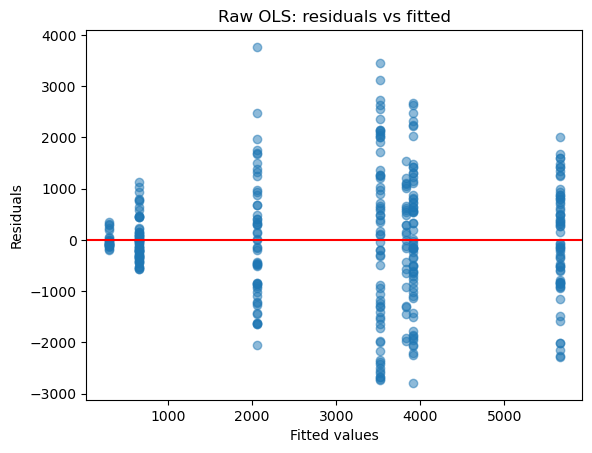

In [3]:
import matplotlib.pyplot as plt
plt.scatter(model_raw.fittedvalues, model_raw.resid, alpha=0.5)
plt.axhline(0, color="red")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Raw OLS: residuals vs fitted")
plt.show()

In [4]:
import numpy as np
model_log =smf.ols("np.log(ride_count) ~ C(season) * C(day_type)", data=daily).fit()
print(model_log.summary())

                            OLS Regression Results                            
Dep. Variable:     np.log(ride_count)   R-squared:                       0.711
Model:                            OLS   Adj. R-squared:                  0.705
Method:                 Least Squares   F-statistic:                     125.4
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           3.74e-92
Time:                        13:58:11   Log-Likelihood:                -337.03
No. Observations:                 365   AIC:                             690.1
Df Residuals:                     357   BIC:                             721.3
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

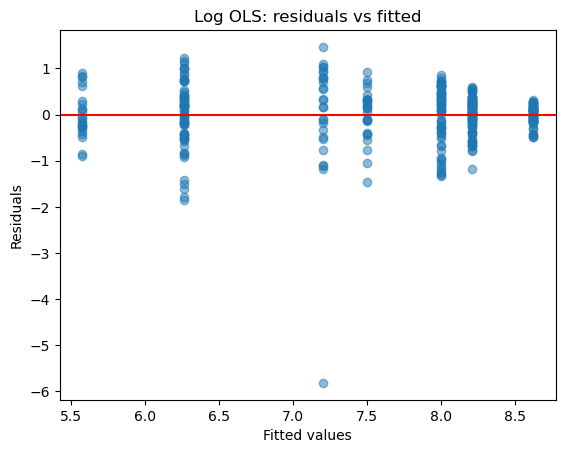

In [5]:
import matplotlib.pyplot as plt
plt.scatter(model_log.fittedvalues, model_log.resid, alpha=0.5)
plt.axhline(0, color="red")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Log OLS: residuals vs fitted")
plt.show()

In [6]:
import statsmodels.api as sm 
anova = sm.stats.anova_lm(model_log, typ=2)
anova 
anova["partial_eta_sq"] = anova["sum_sq"] / (anova["sum_sq"] + anova.loc["Residual", "sum_sq"])
anova.round(3)

,sum_sq,df,F,PR(>F),partial_eta_sq
C(season),304.291,3.0,267.296,0.000,0.692
C(day_type),31.313,1.0,82.519,0.000,0.188
C(season):C(day_type),1.597,3.0,1.403,0.242,0.012
Residual,135.470,357.0,NaN,NaN,0.500


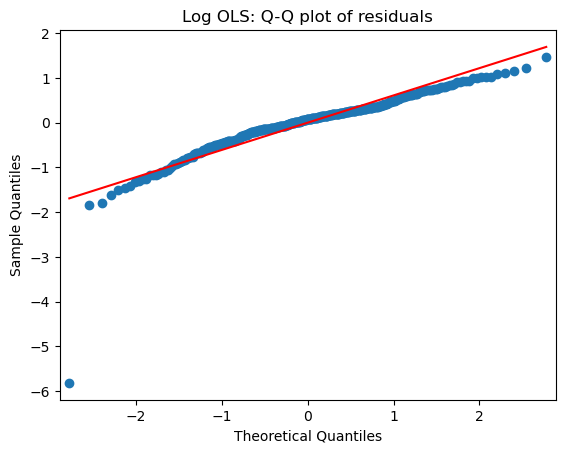

In [7]:
sm.qqplot(model_log.resid, line='s')
plt.title("Log OLS: Q-Q plot of residuals")
plt.show()

0.4968779644239754


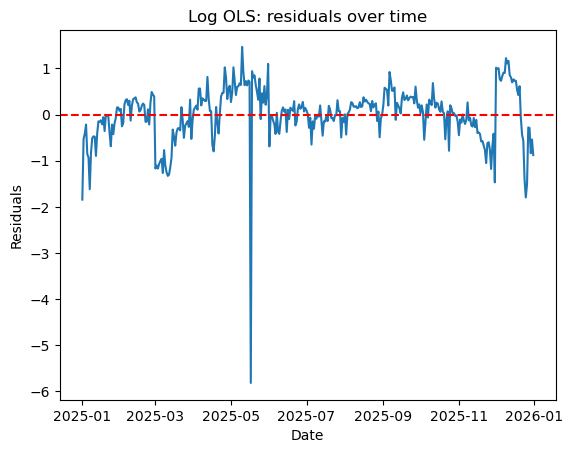

In [8]:
plt.plot(model_log.resid)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Date")
plt.ylabel("Residuals")
plt.title("Log OLS: residuals over time")
print(model_log.resid.autocorr())
plt.show()

In [9]:
daily_clean = daily.drop(pd.Timestamp('2025-05-17'))  # Remove the outlier date from the dataset
print(daily_clean.shape)  # Check the shape of the cleaned dataset


(364, 3)


In [10]:
# Same log model as model_log, but fitted on the data without 17 May (sensitivity analysis)
model_clean = smf.ols("np.log(ride_count) ~ C(season) * C(day_type)", data=daily_clean).fit()
print(model_clean.summary())

                            OLS Regression Results                            
Dep. Variable:     np.log(ride_count)   R-squared:                       0.767
Model:                            OLS   Adj. R-squared:                  0.762
Method:                 Least Squares   F-statistic:                     167.0
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          2.28e-108
Time:                        13:58:12   Log-Likelihood:                -281.93
No. Observations:                 364   AIC:                             579.9
Df Residuals:                     356   BIC:                             611.0
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

In [11]:
# ANOVA + partial eta squared for the model without 17 May, to compare with anova above
anova_clean = sm.stats.anova_lm(model_clean, typ=2)
anova_clean["partial_eta_sq"] = anova_clean["sum_sq"] / (anova_clean["sum_sq"] + anova_clean.loc["Residual", "sum_sq"])
anova_clean.round(3)

,sum_sq,df,F,PR(>F),partial_eta_sq
C(season),306.290,3.0,362.312,0.000,0.753
C(day_type),25.851,1.0,91.738,0.000,0.205
C(season):C(day_type),1.040,3.0,1.230,0.299,0.010
Residual,100.318,356.0,NaN,NaN,0.500
